# Six-cluster comparison: recorded calculations

**Scope.** Conditional host reconstruction, local scattering kernels and Galactic environmental controls for the six shortlisted clusters. No remnant trajectories, residence distributions or diffusion-versus-encounter test have been performed.

**Readout.** Compare reservoir size, central and radial scattering importance, posterior sensitivity and numerical/data suitability. Selected reference rows are not typical hosts. Eight joint draws per cluster are a pilot, not a credible interval.

Sources: the hash-pinned Dickson/GCfit standard fits and Baumgardt orbital table in this repository. The six standard-fit backgrounds define the conditional comparison. NGC 6397 uses its available standard-fit chain; a distinct no-BH alternative has no corresponding chain in the inspected release and is not evaluated. Source-specific applicability information is retained in the data-quality assessment.

The cells read retained products and execute top-to-bottom. Rebuilding the expensive hosts is a separate command in the adjacent README.

In [1]:
from pathlib import Path
import csv, json, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results/cluster-comparison').is_dir())
DATA = ROOT / 'results/cluster-comparison'
load = lambda p: json.loads(p.read_text())
summary = load(DATA/'summary.json')
runs = summary['runs']
assert summary['attempted'] == summary['planned'] == 54
names = {'NGC0104':'47 Tuc','NGC1851':'NGC 1851','NGC3201':'NGC 3201','NGC5139':'Omega Centauri','NGC6121':'M4','NGC6397':'NGC 6397 (standard fit)'}
print(f"{sum(r['kind']=='reference' for r in runs)} reference hosts; {sum(r['kind']=='pilot' for r in runs)} pilot attempts")

6 reference hosts; 48 pilot attempts


## Reference models and local scattering
All six references use the same selection rule, 60-solar-mass diagnostic probe and unit constant Coulomb logarithm. Diffusion shares refer to zero remnant velocity, not orbital residence.

In [2]:
with (DATA/'reference-comparison.csv').open() as f:
    rows = list(csv.DictReader(f))
text = '| Cluster | Expected BH count | Central BH diffusion share | Share at 0.1 rh |\n|---|---:|---:|---:|'
for r in rows:
    text += f"\n| {names[r['cluster']]} | {float(r['BH_expected_number']):.3g} | {100*float(r['BH_D_fraction_center_v0']):.3f}% | {100*float(r['BH_D_fraction_at_0p1rh_v0']):.4g}% |"
display(Markdown(text))

| Cluster | Expected BH count | Central BH diffusion share | Share at 0.1 rh |
|---|---:|---:|---:|
| 47 Tuc | 65.9 | 81.579% | 0.01328% |
| NGC 1851 | 16 | 99.542% | 0.0004788% |
| NGC 3201 | 4.28 | 95.836% | 0.0846% |
| Omega Centauri | 1.21e+04 | 99.999% | 98.52% |
| M4 | 5.33 | 99.431% | 0.02131% |
| NGC 6397 (standard fit) | 2.94 | 97.793% | 3.344e-12% |

## Radial variation across reconstructed joint rows
Blue curves are reference rows; gray curves are accepted pilot realizations. Curves join sampled points and are not a confidence band or a validated trajectory interpolator.

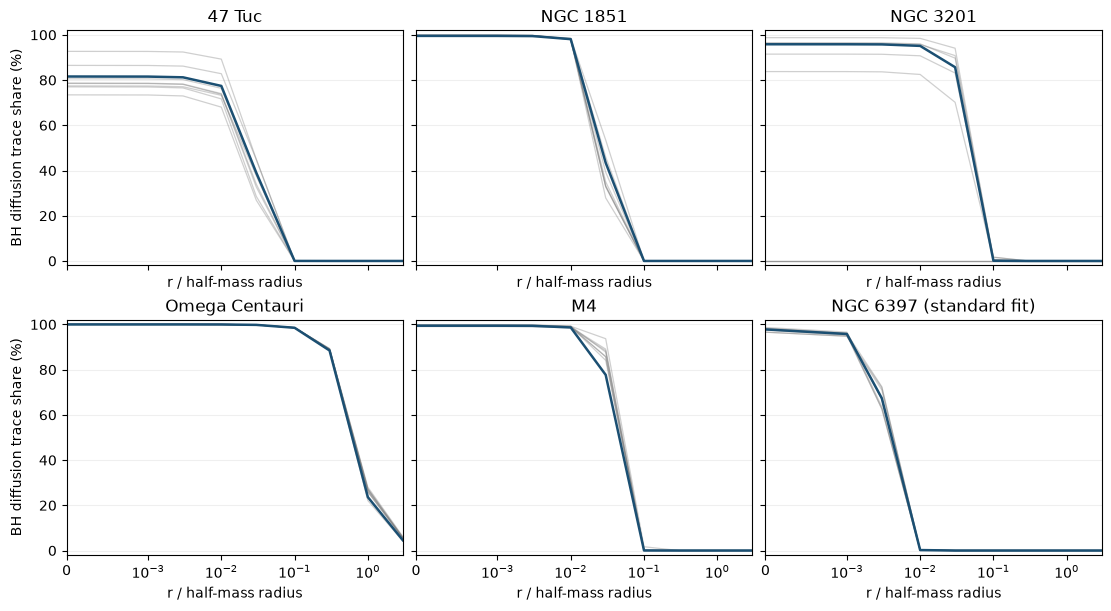

In [3]:
fig, axes = plt.subplots(2,3,figsize=(11,6),sharex=True,sharey=True,layout='constrained')
for ax, (cluster, name) in zip(axes.flat,names.items()):
    selected = [r for r in runs if r['cluster']==cluster and r['host_status']=='passed' and r.get('core_profile_status')=='passed']
    for row in sorted(selected,key=lambda r:r['kind']=='reference'):
        profile = row['core_profile']; reference = row['kind']=='reference'
        ax.plot([p['r_over_rh'] for p in profile],[100*p['BH_trace_D_fraction'] for p in profile],color='#1b4f72' if reference else '#777777',alpha=1 if reference else .35,lw=1.8 if reference else .9)
    ax.set_title(name); ax.set_xscale('symlog',linthresh=.001); ax.set_ylim(-2,102); ax.set_xlim(0,3)
    ax.grid(axis='y',alpha=.2); ax.set_xlabel('r / half-mass radius')
for ax in axes[:,0]: ax.set_ylabel('BH diffusion trace share (%)')
plt.show()

## Released derived-model distribution
These 4,000 realizations per cluster are a separate published product. Their original generating seed and raw-row mapping are unavailable. No new observational fit or direct BH census is implied.

In [4]:
inventory = load(DATA/'posterior-inventory.json')['clusters']
text = '| Cluster | BH count median [16th,84th] | Zero-BH rows |\n|---|---:|---:|'
for row in inventory:
    q=row['BH_expected_number']
    text += f"\n| {names[row['cluster']]} | {q['median']:.3g} [{q['p16']:.3g}, {q['p84']:.3g}] | {row['zero_BH_rows']}/{row['derived_rows']} |"
display(Markdown(text))

| Cluster | BH count median [16th,84th] | Zero-BH rows |
|---|---:|---:|
| 47 Tuc | 61.9 [51.2, 81.1] | 0/4000 |
| NGC 1851 | 15 [13.1, 17.6] | 0/4000 |
| NGC 3201 | 0.926 [0, 4.13] | 1899/4000 |
| Omega Centauri | 1.24e+04 [1.21e+04, 1.3e+04] | 0/4000 |
| M4 | 6.17 [3.99, 9.65] | 28/4000 |
| NGC 6397 (standard fit) | 3.08 [2.84, 3.31] | 0/4000 |

## Numerical acceptance and missing information
An absent BH population is retained; undefined subsystem radii and reservoir ratios are not filled with zero. Failed numerical attempts remain inspectable. Source/model suitability is separate from numerical acceptance.

In [5]:
for cluster,name in names.items():
    pilot=[r for r in runs if r['cluster']==cluster and r['kind']=='pilot']
    accepted=sum(r['host_status']=='passed' for r in pilot)
    absent=sum(r.get('BH_metrics',{}).get('BH_absent',False) for r in pilot)
    print(f'{name}: {accepted}/{len(pilot)} pilot hosts accepted; {absent} absent-BH cases')
    for row in pilot:
        if row['host_status']!='passed': print('  unresolved:',row['label'],row.get('failure_log','')[-300:])

47 Tuc: 8/8 pilot hosts accepted; 0 absent-BH cases
NGC 1851: 8/8 pilot hosts accepted; 0 absent-BH cases
NGC 3201: 8/8 pilot hosts accepted; 3 absent-BH cases
Omega Centauri: 8/8 pilot hosts accepted; 0 absent-BH cases
M4: 7/8 pilot hosts accepted; 0 absent-BH cases
  unresolved: pilot-06 it/core/data.py", line 1697, in __init__
    super().__init__(observations=observations, **theta, **kwargs)
  File "<repo>/tmp/host-venv/lib/python3.11/site-packages/gcfit/core/data.py", line 1194, in __init__
    raise ValueError(mssg)
ValueError: Model solver failed to converge to a finite extent

NGC 6397 (standard fit): 8/8 pilot hosts accepted; 0 absent-BH cases


## Environmental controls
Four distance cases per cluster and three static circular controls are conditional calculations. The force-domain bound is instantaneous and sufficient; it is not a remnant escape boundary.

In [6]:
with (ROOT/'results/cluster-comparison-environment/comparison.csv').open() as f: environment=list(csv.DictReader(f))
text='| Cluster | Static Jacobi scale (pc) | Refined 1% force domain (pc) | Numerical checks | Catalog extrema within 5% |\n|---|---:|---:|---|---|'
for row in environment:
    text+=f"\n| {names[row['cluster']]} | {float(row['static_rJ_pc']):.2f} | {float(row['refined_minimum_1pct_radius_pc']):.3f} | {row['all_numerical_checks_passed']} | {row['catalog_orbit_within_5pct']} |"
display(Markdown(text))

| Cluster | Static Jacobi scale (pc) | Refined 1% force domain (pc) | Numerical checks | Catalog extrema within 5% |
|---|---:|---:|---|---|
| 47 Tuc | 131.38 | 12.569 | True | True |
| NGC 1851 | 159.65 | 1.017 | True | True |
| NGC 3201 | 84.13 | 8.173 | True | True |
| Omega Centauri | 179.48 | 8.748 | True | True |
| M4 | 55.39 | 1.031 | True | False |
| NGC 6397 (standard fit) | 55.29 | 3.477 | True | True |

## Interpretation

Population size and local diffusion importance are distinct. The radial profiles identify where a later encounter comparison should be resolved; they do not establish whether the diffusion approximation fails or changes residence. The pilot variation cannot be treated as converged posterior uncertainty. M4 has one unresolved pilot reconstruction; its catalog-distance orbit passes numerical checks but differs by 20.6% from the published mean pericenter. Neither discrepancy is concealed by selecting another case.

The adopted backgrounds are spherical, nonrotating standard fits. NGC 3201 provides a conditional sparse-population reference; NGC 6397 uses the available standard-fit chain, with its distinct no-BH alternative left unevaluated. Rotation, binary populations, discrete counts, backreaction and physical scattering cutoffs require separate specifications for a matched encounter experiment. The data-quality assessment records source-specific applicability information alongside these experimental assumptions.

See `docs/six-cluster-comparison.md`, `docs/six-cluster-data-quality.md`, and `docs/six-cluster-environment.md`. Source URLs and exact hashes are retained in `data/observed-clusters/sources.json`, the per-cluster selection records, and the comparison provenance manifest.